# Sensor preprocessing and occupancy analysis

Place complete environmental and occupancy CSV exports in `data` (subfolders are searched too), then run the preprocessing cell first. The analysis uses the processed occupancy streams only: select one floorspace and one semester to scatter-plot each valid Monday-to-Friday headcount record without averaging. Environmental measurements are not used in this occupancy analysis.

In [2]:
# Standard-library imports handle parsing, validation, filesystem operations, timing, and focused tests.
import json
import math
import os
import re
import shutil
import tempfile
import time
import unittest
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

# The notebook is intentionally run from the repository root, so all project paths are deterministic.
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
# Repository-relative paths keep inputs, outputs, and reports in predictable locations.
DERIVED = ROOT / "derived"
ENV_OUTPUT_DIR = DERIVED / "environmental_measurements"
PREPROCESSING_OUTPUT_DIR = DERIVED / "preprocessing"
LEGACY_ENV_CSV = ROOT / "5EnvSensor_MayToDec2024_180kRows.csv"
LEGACY_OCC_CSV = ROOT / "5occupancySensor_MayToDec2024_9MRows.csv"
ENV_LOOKUP_NAME = "Sensor ID and Locations - ENV.csv"
ENV_LOOKUP = DATA_DIR / ENV_LOOKUP_NAME if (DATA_DIR / ENV_LOOKUP_NAME).is_file() else ROOT / ENV_LOOKUP_NAME
ENV_FULL = ENV_OUTPUT_DIR / "environmental_measurements_wide.csv"
ENV_REDUCED = ENV_OUTPUT_DIR / "environmental_measurements_wide_reduced.csv"
ENV_SCHEMA = ENV_OUTPUT_DIR / "environmental_measurements_wide_schema.csv"
ENV_VALIDATION = ENV_OUTPUT_DIR / "environmental_measurements_wide_validation.csv"
ENV_BENCHMARK = ENV_OUTPUT_DIR / "environmental_measurements_wide_benchmark.csv"
OCC_STREAMS = DERIVED / "occupancy_streams_by_floorspace"
MISSING_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_missing_data_report.csv"
CHANGE_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_changes.csv"
VALIDATION_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_validation.csv"
BENCHMARK_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_benchmark.csv"
STAGE_COMPARISON_REPORT = PREPROCESSING_OUTPUT_DIR / "preprocessing_raw_vs_processed_benchmark.csv"
# A fixed chunk size bounds intermediate CSV memory; it is a processing parameter, not a data filter.
CHUNK = 50_000
# These source identifiers are strict project-specific invariants checked before outputs are published.
SENSOR_ID = 6012000000000
DEVICE_ID = "56923747-b390-4f2a-8930-808429132266"
# Only these explicit textual tokens are normalized as missing; other malformed values are errors.
MISSING = {"", "nan", "null", "none"}
# These ordered required fields define the supported environmental CSV input contract.
ENV_COLS = ["id", "sensorid", "devicetype", "jsondata", "status", "processing_errors", "createdate", "processdate"]
# These ordered required fields define the supported occupancy CSV input contract.
OCC_COLS = ["id", "deviceid", "floorspaceid", "occupancystatus", "headcount", "collecteddate", "occupancystatuschangedate", "previousoccupancystatus"]
validation, changes, missing_report, benchmarks = [], [], [], []


def add_validation(check, result, observed, expected, notes=""):
    # Keep validation outcomes in memory until the complete run writes one consolidated report.
    validation.append({"check": check, "result": result, "observed": observed, "expected": expected, "notes": notes})


def add_change(dataset, source, output, operation, columns, reason, affected=0, before="", after=""):
    # Store repository-relative paths so the audit remains portable across machines.
    def relative(path):
        try:
            return Path(path).relative_to(ROOT).as_posix()
        except ValueError:
            return str(path)
    changes.append({"dataset": dataset, "source_file": relative(source), "output_file": relative(output), "operation": operation, "columns": columns, "reason": reason, "affected_rows": affected, "input_rows": before, "output_rows": after, "result": "PASS"})


def atomic_csv(frame, destination):
    # Stage beside the destination so os.replace remains an atomic same-volume operation.
    destination = Path(destination)
    # Create report folders lazily, including when the repository is freshly cloned.
    destination.parent.mkdir(parents=True, exist_ok=True)
    temp = None
    try:
        # Write to a sibling temporary file so a failed report write cannot truncate the existing report.
        with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", newline="", suffix=".csv", prefix=f".{destination.stem}.", dir=destination.parent, delete=False) as stream:
            temp = Path(stream.name)
            frame.to_csv(stream, index=False, lineterminator="\n", na_rep="NaN")
        os.replace(temp, destination)
        temp = None
    # Clean up the temporary artifact even when serialization or replacement raises.
    finally:
        if temp is not None and temp.exists():
            temp.unlink()


def discover_latest_csv(data_dir, required_columns, signature_columns, legacy_path, dataset):
    data_dir = Path(data_dir)
    required_columns = set(required_columns)
    signature_columns = set(signature_columns)
    matches, unsupported = [], []
    if data_dir.is_dir():
        # Search nested directories deterministically, but select by modification time rather than traversal order.
        for path in sorted(data_dir.rglob("*.csv")):
            if path.name == ENV_LOOKUP_NAME:
                continue
            headers = set(pd.read_csv(path, nrows=0, dtype=str, keep_default_na=False).columns)
            if required_columns.issubset(headers):
                matches.append(path)
            # Treat a file with dataset-specific signature fields but missing required fields as an invalid export, not as an unrelated CSV.
            elif headers & signature_columns:
                unsupported.append((path, sorted(required_columns - headers)))
    if unsupported:
        details = "; ".join(f"{path.name}: missing {missing}" for path, missing in unsupported)
        raise ValueError(f"{dataset}: raw CSV has an unsupported/incomplete schema: {details}")
    if matches:
        # Compare exact filesystem modification times and require the user to resolve a tie.
        newest_time = max(path.stat().st_mtime_ns for path in matches)
        newest = [path for path in matches if path.stat().st_mtime_ns == newest_time]
        if len(newest) != 1:
            raise ValueError(f"{dataset}: multiple matching exports share the newest modification time: {[path.name for path in newest]}")
        return newest[0], len(matches), "data"
    # The root-level path is a compatibility fallback only when the data folder has no matching export.
    legacy_path = Path(legacy_path)
    if legacy_path.is_file():
        return legacy_path, 0, "legacy"
    raise FileNotFoundError(f"{dataset}: no schema-matching CSV under {data_dir} and no legacy input at {legacy_path}")


# Select a complete replacement export per sensor family; never concatenate snapshots.
ENV_CSV, env_export_count, env_selection_source = discover_latest_csv(DATA_DIR, ENV_COLS, {"jsondata", "sensorid"}, LEGACY_ENV_CSV, "environmental")
OCC_CSV, occ_export_count, occ_selection_source = discover_latest_csv(DATA_DIR, OCC_COLS, {"floorspaceid", "headcount", "collecteddate"}, LEGACY_OCC_CSV, "occupancy")
for dataset, path, export_count, source in (
    ("environmental", ENV_CSV, env_export_count, env_selection_source),
    ("occupancy", OCC_CSV, occ_export_count, occ_selection_source),
):
    selected = path.relative_to(ROOT).as_posix()
    if source == "data":
        add_validation(f"{dataset}_input_selection", "PASS", selected, "newest complete export under data", f"Selected from {export_count} schema-matching export(s) by modification time; other exports were not combined.")
    else:
        add_validation(f"{dataset}_input_selection", "INFO", selected, "newest complete export under data", "No matching export was found under data; used the legacy project-root input.")


def numeric_or_nan(series, label):
    # Keep missing tokens distinct from zero and reject invalid nonmissing values.
    text = series.astype("string").str.strip()
    # Separate explicit missing markers before numeric conversion so they never become zero.
    missing = text.isna() | text.str.casefold().isin(MISSING)
    numeric = pd.to_numeric(text.mask(missing), errors="coerce")
    # A conversion failure is only an error for a nonmissing input token.
    bad = (~missing) & numeric.isna()
    if bad.any():
        raise ValueError(f"{label}: non-numeric value {text.loc[bad].iloc[0]!r}")
    # Reject infinities as well as nonnumeric text because neither is a valid measurement.
    if (numeric.dropna().map(math.isfinite) == False).any():
        raise ValueError(f"{label}: non-finite numeric value")
    return numeric, missing


def feature_slug(value):
    value = str(value).casefold().replace("2.5", "2_5")
    # Keep generated feature names deterministic and safe as CSV column labels.
    return re.sub(r"[^a-z0-9]+", "_", value).strip("_") or "unnamed"


def validate_env_lookup():
    lookup = pd.read_csv(ENV_LOOKUP, dtype=str, keep_default_na=False)
    if lookup.empty or not {"Sensor", "ID"}.issubset(lookup.columns):
        raise ValueError(f"{ENV_LOOKUP.name}: required Sensor/ID columns or rows missing")
    # Validate lookup IDs numerically so formatting such as scientific notation does not evade the sensor check.
    ids = pd.to_numeric(lookup["ID"], errors="coerce")
    if not lookup["Sensor"].eq("Env").all() or ids.isna().any() or not ids.eq(SENSOR_ID).all():
        raise ValueError(f"{ENV_LOOKUP.name}: unexpected sensor or ID")
    add_validation("ENV_location_lookup", "PASS", len(lookup), "Sensor=Env; ID=6012000000000")


def parse_json_payload(raw, record_id):
    try:
        payload = json.loads(raw)
    # Attach the source record ID to parse errors so a bad payload can be traced back to raw data.
    except (json.JSONDecodeError, TypeError) as exc:
        raise ValueError(f"Environmental record {record_id}: invalid JSON") from exc
    if not isinstance(payload, list):
        raise ValueError(f"Environmental record {record_id}: payload is not a list")
    # Collect values and enforce one consistent measurement instant per source record.
    measurements, metadata, times = {}, {}, set()
    for entry in payload:
        # Reject structurally incomplete JSON rather than silently dropping a variable.
        if not isinstance(entry, dict) or not isinstance(entry.get("variable"), dict):
            raise ValueError(f"Environmental record {record_id}: malformed measurement")
        variable = entry["variable"]
        var_id = str(variable.get("id", ""))
        if not var_id.isdigit() or var_id in measurements:
            raise ValueError(f"Environmental record {record_id}: invalid/duplicate variable ID")
        # Retain units and source metadata with each generated variable for later interpretation.
        descriptor = {"variable_id": var_id, "variable": str(variable.get("name", "")), "unit": str(variable.get("unit", "")), "source": str(variable.get("source", "")), "structure": str(variable.get("structure", "")), "output_column": f"var_{var_id}_{feature_slug(variable.get('name', ''))}"}
        metadata[var_id] = descriptor
        points = entry.get("values")
        # The wide transform supports at most one observation per variable in a source event.
        if not isinstance(points, list) or len(points) > 1:
            raise ValueError(f"Environmental record {record_id}: variable {var_id} must have at most one value point")
        # An empty values array indicates a missing measurement, not a zero-valued observation.
        if not points:
            measurements[var_id] = float("nan")
            continue
        if not isinstance(points[0], dict):
            raise ValueError(f"Environmental record {record_id}: variable {var_id} has a malformed value point")
        point = points[0]
        stamp = point.get("time")
        # Booleans are integers in Python, but are not valid Unix timestamps for this dataset.
        if stamp is None or isinstance(stamp, bool):
            raise ValueError(f"Environmental record {record_id}: missing measurement time")
        try:
            times.add(int(stamp))
        except (TypeError, ValueError, OverflowError) as exc:
            raise ValueError(f"Environmental record {record_id}: invalid measurement time") from exc
        value = point.get("value")
        # Preserve JSON null as NaN; do not let the later numeric pipeline interpret it as zero.
        if value is None:
            measurements[var_id] = float("nan")
        else:
            try:
                value = float(value)
            except (TypeError, ValueError, OverflowError) as exc:
                raise ValueError(f"Environmental record {record_id}: non-numeric variable {var_id}") from exc
            if not math.isfinite(value):
                raise ValueError(f"Environmental record {record_id}: non-finite variable {var_id}")
            measurements[var_id] = value
    # All feature measurements in one source event must share one timestamp for a coherent wide row.
    if len(times) != 1:
        raise ValueError(f"Environmental record {record_id}: expected one shared measurement timestamp")
    timestamp = datetime.fromtimestamp(next(iter(times)), tz=timezone.utc).isoformat().replace("+00:00", "Z")
    return timestamp, measurements, metadata


def build_environmental_outputs():
    # Inspect only headers first; this fails early before an expensive full-data pass.
    headers = list(pd.read_csv(ENV_CSV, nrows=0, dtype=str, keep_default_na=False).columns)
    if not set(ENV_COLS).issubset(headers):
        raise ValueError(f"{ENV_CSV.name}: required environmental columns missing: {sorted(set(ENV_COLS) - set(headers))}")
    # First pass establishes the complete feature schema before any wide rows are written.
    descriptors, seen_ids = {}, set()
    row_count = equal_dates = timestamp_pairs = 0
    # Count source missing tokens by field while streaming rather than retaining the full source table.
    raw_missing = dict.fromkeys(ENV_COLS, 0)
    # The first pass validates every source event and discovers all feature metadata before output columns are fixed.
    for chunk in pd.read_csv(ENV_CSV, usecols=ENV_COLS, dtype=str, keep_default_na=False, chunksize=CHUNK):
        chunk = chunk.reindex(columns=ENV_COLS)
        row_count += len(chunk)
        for col in ENV_COLS:
            raw_missing[col] += int(chunk[col].str.strip().str.casefold().isin(MISSING).sum())
        ids = chunk["id"].astype(str)
        # Check uniqueness both within the current chunk and against IDs seen in prior chunks.
        if ids.eq("").any() or ids.duplicated().any() or not seen_ids.isdisjoint(ids):
            raise ValueError("Environmental record IDs are blank or duplicated")
        seen_ids.update(ids)
        sensor = pd.to_numeric(chunk["sensorid"], errors="coerce")
        if sensor.isna().any() or not sensor.eq(SENSOR_ID).all():
            raise ValueError("Unexpected environmental sensor ID")
        # These categorical constants are part of the validated source contract, not inferred assumptions.
        for column, expected in (("devicetype", "env"), ("status", "Processed"), ("processing_errors", "NULL")):
            if not chunk[column].eq(expected).all():
                raise ValueError(f"Unexpected environmental {column}")
        created = pd.to_datetime(chunk["createdate"], errors="coerce", utc=True)
        processed = pd.to_datetime(chunk["processdate"], errors="coerce", utc=True)
        if created.isna().any() or processed.isna().any():
            raise ValueError("Invalid createdate/processdate")
        # Count parsed record-time equality across the full input; dropping processdate requires every row to match.
        equal_dates += int(created.eq(processed).sum())
        timestamp_pairs += len(chunk)
        for record_id, raw in chunk[["id", "jsondata"]].itertuples(index=False, name=None):
            _, _, row_metadata = parse_json_payload(raw, record_id)
            for key, descriptor in row_metadata.items():
                # Stable variable metadata ensures a single output column and unit meaning across records.
                if key in descriptors and descriptors[key] != descriptor:
                    raise ValueError(f"Environmental variable {key}: metadata changes between records")
                descriptors[key] = descriptor
    if row_count == 0 or not descriptors:
        raise ValueError("Environmental input is empty")
    # Numeric sorting keeps feature order stable even when variable IDs have different digit lengths.
    variables = sorted(descriptors, key=int)
    features = [descriptors[key]["output_column"] for key in variables]
    # Distinct source variables must not collapse to the same normalized output name.
    if len(features) != len(set(features)):
        raise ValueError("Measurement variable names collide after normalization")
    schema = pd.DataFrame([descriptors[key] for key in variables])
    atomic_csv(schema, ENV_SCHEMA)

    # Keep source identity and both relevant time concepts explicit in the full output schema.
    columns = ["source_record_id", "sensor_id", "devicetype", "createdate", "processdate", "timestamp_utc", *features]
    missing_by_feature = dict.fromkeys(features, 0)
    temp = None
    written = 0
    try:
        with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", newline="", suffix=".csv", prefix=".environmental-wide.", dir=ENV_OUTPUT_DIR, delete=False) as out:
            temp = Path(out.name)
            first = True
            for chunk in pd.read_csv(ENV_CSV, usecols=ENV_COLS, dtype=str, keep_default_na=False, chunksize=CHUNK):
                chunk = chunk.reindex(columns=ENV_COLS)
                records = []
                # Expand each source event against the schema discovered in the first pass.
                for record in chunk.itertuples(index=False, name=None):
                    record_id, sensor, device, raw_json, _, _, created, processed = record
                    stamp, values, _ = parse_json_payload(raw_json, record_id)
                    item = {"source_record_id": record_id, "sensor_id": str(SENSOR_ID), "devicetype": device, "createdate": created, "processdate": processed, "timestamp_utc": stamp}
                    # Use NaN for a variable absent from a record so every row shares one rectangular schema.
                    for key in variables:
                        item[descriptors[key]["output_column"]] = values.get(key, float("nan"))
                    records.append(item)
                # Construct each bounded output batch only after parsing the source chunk.
                expanded = pd.DataFrame(records, columns=columns)
                for feature in features:
                    normalized, is_missing = numeric_or_nan(expanded[feature], feature)
                    missing_by_feature[feature] += int(is_missing.sum())
                    expanded[feature] = normalized
                expanded.to_csv(out, index=False, header=first, lineterminator="\n", na_rep="NaN")
                first = False
                written += len(expanded)
        if written != row_count:
            raise ValueError(f"Wide output has {written} rows; expected {row_count}")
        # Publish only after row-count validation; replacement avoids exposing a partially written CSV.
        os.replace(temp, ENV_FULL)
        temp = None
    finally:
        if temp is not None and temp.exists():
            temp.unlink()

    # Remove fields only after their invariance has been checked across the full input.
    excluded = {"sensor_id", "devicetype"}
    # Drop processdate only when equality holds for every parsed row, never based on a sample.
    if equal_dates == timestamp_pairs:
        excluded.add("processdate")
    selected = [col for col in columns if col not in excluded]
    temp = None
    reduced_rows = 0
    try:
        with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", newline="", suffix=".csv", prefix=".environmental-reduced.", dir=ENV_OUTPUT_DIR, delete=False) as out:
            temp = Path(out.name)
            first = True
            # Build the reduced file from the validated full output so it is a deterministic column selection.
            for chunk in pd.read_csv(ENV_FULL, usecols=selected, dtype=str, keep_default_na=False, chunksize=CHUNK):
                for feature in features:
                    chunk[feature], _ = numeric_or_nan(chunk[feature], feature)
                chunk.to_csv(out, index=False, header=first, lineterminator="\n", na_rep="NaN")
                first = False
                reduced_rows += len(chunk)
        if reduced_rows != row_count:
            raise ValueError("Reduced environmental output changed the row count")
        os.replace(temp, ENV_REDUCED)
        temp = None
    finally:
        if temp is not None and temp.exists():
            temp.unlink()

    # Reports describe checks performed on the complete source, not only the current chunk.
    add_validation("environmental_rows_and_json", "PASS", f"{row_count:,} rows; {len(features)} variables", "one valid wide row per raw record")
    add_validation("environmental_ids", "PASS", len(seen_ids), row_count, "unique and nonblank")
    add_validation("environmental_constants", "PASS", "sensorid/devicetype/status/processing_errors", "all expected constants")
    add_validation("environmental_record_timestamps", "PASS" if equal_dates == timestamp_pairs else "INFO", f"{equal_dates:,}/{timestamp_pairs:,} equal", "parseable timestamps; equality required to drop processdate")
    add_change("environmental", ENV_CSV, ENV_FULL, "expand_json_to_wide", "jsondata -> measurement columns", "One wide row per source record; raw JSON left untouched.", row_count, row_count, written)
    add_change("environmental", ENV_CSV, ENV_FULL, "normalize_missing_measurements_to_NaN", ",".join(features), "Empty values arrays, JSON nulls, and absent variables become NaN in derived measurements.", sum(missing_by_feature.values()), row_count, written)
    add_change("environmental", ENV_FULL, ENV_REDUCED, "exclude_verified_columns", ",".join(sorted(excluded)), "Remove validated constants and equal processdate; retain measurement timestamp.", row_count, row_count, reduced_rows)
    for feature, count in missing_by_feature.items():
        missing_report.append({"dataset": "environmental", "column": feature, "missing_type": "missing_measurement", "count": count, "handling": "NaN in derived wide outputs; raw JSON and source rows unchanged."})
    return {"rows": row_count, "features": features, "columns": columns, "selected": selected, "excluded": sorted(excluded), "missing": missing_by_feature, "timestamp_equal": equal_dates}


def validate_wide_file(path, raw_rows, reduced):
    schema = pd.read_csv(ENV_SCHEMA, dtype=str, keep_default_na=False)
    features = schema["output_column"].tolist()
    headers = list(pd.read_csv(path, nrows=0, dtype=str, keep_default_na=False).columns)
    # Require identifiers, both relevant timestamps, and every feature listed by the generated schema.
    expected = set(["source_record_id", "createdate", "timestamp_utc", *features])
    if not expected.issubset(headers):
        raise ValueError(f"{path.name}: required output columns missing")
    if not reduced and not {"sensor_id", "devicetype", "processdate"}.issubset(headers):
        raise ValueError(f"{path.name}: full output columns missing")
    # Track IDs across chunks to catch duplicates that are separated in the file.
    ids, rows = set(), 0
    for chunk in pd.read_csv(path, dtype=str, keep_default_na=False, chunksize=CHUNK):
        rows += len(chunk)
        chunk_ids = chunk["source_record_id"].astype(str)
        if chunk_ids.eq("").any() or chunk_ids.duplicated().any() or not ids.isdisjoint(chunk_ids):
            raise ValueError(f"{path.name}: duplicate/blank source record ID")
        ids.update(chunk_ids)
        if pd.to_datetime(chunk["timestamp_utc"], errors="coerce", utc=True).isna().any():
            raise ValueError(f"{path.name}: invalid measurement timestamp")
        for feature in features:
            numeric_or_nan(chunk[feature], feature)
    if rows != raw_rows or len(ids) != raw_rows:
        raise ValueError(f"{path.name}: row/ID count differs from raw input")
    add_validation(f"{path.stem}_schema_rows_ids", "PASS", f"{rows:,} rows; {len(headers)} columns", f"{raw_rows:,} matching unique IDs", "Measurement fields are numeric or NaN.")


def audit_change_date(path):
    data = pd.read_csv(path, usecols=["id", "headcount", "collecteddate", "occupancystatuschangedate"], dtype=str, keep_default_na=False)
    ids = pd.to_numeric(data["id"], errors="coerce")
    count, _ = numeric_or_nan(data["headcount"], "headcount")
    collected = pd.to_datetime(data["collecteddate"], errors="coerce", utc=True)
    changed = pd.to_datetime(data["occupancystatuschangedate"], errors="coerce", utc=True)
    if ids.isna().any() or collected.isna().any() or changed.isna().any():
        raise ValueError(f"{path.name}: invalid ID or timestamp in change-date audit")
    # Sort events into time order before using shifted rows to compare adjacent occupancy states.
    data = data.assign(_id=ids, _count=count, _collected=collected, _changed=changed).sort_values(["_collected", "_id"], kind="stable").reset_index(drop=True)
    # Shifted values represent the preceding event after sorting, enabling zero-to-positive and positive-run checks.
    previous_count, previous_changed = data["_count"].shift(), data["_changed"].shift()
    zero, positive = data["_count"].eq(0), data["_count"].gt(0)
    starts, runs = positive & previous_count.eq(0), positive & previous_count.gt(0)
    zero_match = zero & data["_changed"].eq(data["_collected"])
    start_match = starts & data["_changed"].eq(data["_collected"])
    run_match = runs & data["_changed"].eq(previous_changed)
    start_bad = starts & ~data["_changed"].eq(data["_collected"])
    run_bad = runs & ~data["_changed"].eq(previous_changed)
    # Return counts and first exception IDs so patterns can be reviewed without retaining the entire stream.
    return {"floorspaceid": path.stem, "rows": len(data), "zero_readings": int(zero.sum()), "zero_time_matches": int(zero_match.sum()), "positive_starts_after_zero": int(starts.sum()), "positive_start_time_matches": int(start_match.sum()), "positive_start_first_exception_id": str(data.loc[start_bad, "id"].iloc[0]) if start_bad.any() else "", "successive_positive_pairs": int(runs.sum()), "unchanged_time_in_positive_run": int(run_match.sum()), "positive_run_time_changes": int(run_bad.sum()), "positive_run_first_exception_id": str(data.loc[run_bad, "id"].iloc[0]) if run_bad.any() else ""}


def build_occupancy_streams():
    headers = list(pd.read_csv(OCC_CSV, nrows=0, dtype=str, keep_default_na=False).columns)
    if not set(OCC_COLS).issubset(headers):
        raise ValueError(f"{OCC_CSV.name}: required occupancy columns missing: {sorted(set(OCC_COLS) - set(headers))}")
    # Stage large partitioned outputs outside the final directory; incomplete runs should not appear as completed streams.
    temp_root = Path(tempfile.mkdtemp(prefix=".occupancy-preprocessing."))
    staging, final = temp_root / "staging", temp_root / "final"
    staging.mkdir()
    final.mkdir()
    rows_by_space, source_rows = {}, 0
    unknown = blank_previous = timestamp_equal = 0
    # Accumulate missing-token counts by original field while reading occupancy chunks.
    raw_missing = dict.fromkeys(OCC_COLS, 0)
    count_min = count_max = None
    try:
        for chunk in pd.read_csv(OCC_CSV, usecols=OCC_COLS, dtype=str, keep_default_na=False, chunksize=CHUNK):
            chunk = chunk.reindex(columns=OCC_COLS)
            source_rows += len(chunk)
            for col in OCC_COLS:
                raw_missing[col] += int(chunk[col].str.strip().str.casefold().isin(MISSING).sum())
            if not chunk["deviceid"].eq(DEVICE_ID).all():
                raise ValueError("Unexpected occupancy deviceid")
            if chunk["floorspaceid"].str.strip().str.casefold().isin(MISSING).any():
                raise ValueError("Occupancy floorspaceid is missing")
            headcount, _ = numeric_or_nan(chunk["headcount"], "occupancy headcount")
            # Apply range and integrality checks only to observed counts; NaN is allowed and retained.
            valid = headcount.dropna()
            if (valid < 0).any() or ((valid % 1) != 0).any():
                raise ValueError("Occupancy headcount must be a nonnegative integer or missing")
            if not valid.empty:
                count_min = valid.min() if count_min is None else min(count_min, valid.min())
                count_max = valid.max() if count_max is None else max(count_max, valid.max())
            collected = pd.to_datetime(chunk["collecteddate"], errors="coerce", utc=True)
            changed = pd.to_datetime(chunk["occupancystatuschangedate"], errors="coerce", utc=True)
            if collected.isna().any() or changed.isna().any():
                raise ValueError("Occupancy timestamps contain invalid values")
            timestamp_equal += int(collected.eq(changed).sum())
            # Normalize case/whitespace only for counting unknown history; raw categories remain untouched.
            previous = chunk["previousoccupancystatus"].str.strip().str.casefold()
            unknown += int(previous.eq("unknown").sum())
            blank_previous += int(previous.isin(MISSING).sum())
            chunk["headcount"] = headcount
            # Partition each chunk by location to avoid loading the multi-million-row source at once.
            for space, group in chunk[["id", "floorspaceid", "headcount", "collecteddate", "occupancystatuschangedate"]].groupby("floorspaceid", sort=False):
                # Reject path separators and Windows-invalid filename characters before using a floorspace ID as a filename.
                if any(char in space for char in '<>:"/\\|?*') or space.rstrip(" .") != space:
                    raise ValueError(f"Invalid floorspace ID for output filename {space!r}")
                path = staging / f"{space}.csv"
                group.to_csv(path, mode="a" if path.exists() else "w", header=not path.exists(), index=False, lineterminator="\n", na_rep="NaN")
                rows_by_space[space] = rows_by_space.get(space, 0) + len(group)
        if source_rows == 0:
            raise ValueError("Occupancy source is empty")
        audits = []
        # Audit the change timestamp while available, then omit it from the analytical streams.
        for space in sorted(rows_by_space):
            source = staging / f"{space}.csv"
            # Audit the temporary stream that still contains the change timestamp, before creating the reduced analytical stream.
            audit = audit_change_date(source)
            if audit["rows"] != rows_by_space[space]:
                raise ValueError(f"{source.name}: change-date audit row mismatch")
            audits.append(audit)
            target = final / source.name
            first, count = True, 0
            for chunk in pd.read_csv(source, dtype=str, keep_default_na=False, chunksize=CHUNK):
                # Drop only after the audit; the output retains the observation timestamp and headcount.
                chunk.drop(columns=["occupancystatuschangedate"]).to_csv(target, mode="w" if first else "a", header=first, index=False, lineterminator="\n", na_rep="NaN")
                count += len(chunk)
                first = False
            # Check per-partition conservation before publishing any staged stream.
            if count != rows_by_space[space]:
                raise ValueError(f"{target.name}: output row count mismatch")
        pd.DataFrame([{"floorspaceid": key, "row_count": value} for key, value in rows_by_space.items()]).to_csv(final / "stream_row_counts.csv", index=False)
        audit_frame = pd.DataFrame(audits)
        audit_frame.to_csv(final / "occupancystatuschangedate_audit.csv", index=False)
        # Publish validated staged files individually for safer replacement on Windows/OneDrive.
        if OCC_STREAMS.exists():
            staged_names = {path.name for path in final.iterdir()}
            if any(path.is_dir() for path in OCC_STREAMS.iterdir()):
                raise ValueError(f"Unexpected subdirectory in derived occupancy output: {OCC_STREAMS}")
            for staged_file in final.iterdir():
                os.replace(staged_file, OCC_STREAMS / staged_file.name)
            # Remove obsolete prior partitions only after every replacement partition has been staged and validated.
            for stale_file in OCC_STREAMS.iterdir():
                if stale_file.name not in staged_names:
                    stale_file.unlink()
        else:
            final.rename(OCC_STREAMS)
        add_validation("occupancy_rows_and_spaces", "PASS", f"{source_rows:,} rows; {len(rows_by_space)} spaces", "all source rows retained")
        add_validation("occupancy_device_constant", "PASS", DEVICE_ID, "constant across all rows")
        add_validation("occupancy_timestamps", "PASS", f"all parseable; {timestamp_equal:,}/{source_rows:,} equal", "parseable; equality reported")
        add_validation("occupancy_headcount", "PASS", f"numeric integer range {count_min}-{count_max}", "nonnegative integer or NaN")
        add_validation("occupancy_previous_unknown", "INFO", unknown, "counted and omitted from derived streams")
        add_change("occupancy", OCC_CSV, OCC_STREAMS, "split_by_floorspace", "deviceid,occupancystatus,previousoccupancystatus", "Validate deviceid; omit validated constant ID and category/history fields from selected derived series.", source_rows, source_rows, source_rows)
        add_change("occupancy", OCC_CSV, OCC_STREAMS, "count_and_exclude_unknown_history", "previousoccupancystatus", "Unknown values are counted in the missingness report; the history column is omitted from derived streams.", unknown, source_rows, source_rows)
        add_change("occupancy", OCC_CSV, OCC_STREAMS, "normalize_missing_headcount_to_NaN", "headcount", "Missing headcounts remain as NaN without dropping stream rows.", raw_missing["headcount"], source_rows, source_rows)
        add_change("occupancy", OCC_CSV, OCC_STREAMS, "audit_then_drop_change_timestamp", "occupancystatuschangedate", "Write pattern audit before removing the timestamp from derived series.", source_rows, source_rows, source_rows)
        missing_report.extend([
            {"dataset": "occupancy", "column": "previousoccupancystatus", "missing_type": "unknown", "count": unknown, "handling": "Omitted from derived streams; raw CSV unchanged."},
            {"dataset": "occupancy", "column": "previousoccupancystatus", "missing_type": "blank_or_null", "count": blank_previous, "handling": "Omitted from derived streams; raw CSV unchanged."},
            {"dataset": "occupancy", "column": "headcount", "missing_type": "blank_or_null", "count": raw_missing["headcount"], "handling": "NaN in derived stream; rows retained."},
        ])
        return {"rows": source_rows, "spaces": len(rows_by_space), "unknown": unknown, "audit": audit_frame, "selected": ["id", "floorspaceid", "headcount", "collecteddate"]}
    # The staging tree contains only temporary copies and is removed whether the build succeeds or fails.
    finally:
        if temp_root.exists():
            shutil.rmtree(temp_root)


def benchmark_file(path_or_paths, dataset, reduced_columns=None, repeats=3, comparison_group="", representation=""):
    paths = [path_or_paths] if isinstance(path_or_paths, (str, Path)) else list(path_or_paths)
    if not paths:
        raise ValueError(f"{dataset}: no files supplied for benchmark")
    # Confirm every file in a multi-file benchmark has an identical ordered schema before combining counts.
    headers_by_file = [list(pd.read_csv(path, nrows=0, dtype=str, keep_default_na=False).columns) for path in paths]
    headers = headers_by_file[0]
    if any(columns != headers for columns in headers_by_file[1:]):
        raise ValueError(f"{dataset}: benchmark files do not share the same ordered schema")
    selected_columns = headers if reduced_columns is None else list(reduced_columns)
    missing_columns = set(selected_columns) - set(headers)
    if missing_columns or not selected_columns:
        raise ValueError(f"{dataset}: invalid benchmark columns {sorted(missing_columns)}")
    # Compare full parsing with the requested projected columns; no rows are filtered in either case.
    configurations = {"full_read": None, "reduced_read": selected_columns}
    times = {name: [] for name in configurations}
    row_counts = {name: [] for name in configurations}
    largest_chunks = {name: 0 for name in configurations}
    # Alternate read order to reduce systematic first-read/cache bias.
    for iteration in range(repeats):
        order = list(configurations)
        if iteration % 2:
            order.reverse()
        for name in order:
            count = 0
            # Measure the largest in-memory pandas chunk, not total process memory or operating-system cache.
            largest = 0
            started = time.perf_counter()
            for path in paths:
                for chunk in pd.read_csv(path, usecols=configurations[name], chunksize=CHUNK):
                    count += len(chunk)
                    largest = max(largest, int(chunk.memory_usage(index=True, deep=True).sum()))
            times[name].append(time.perf_counter() - started)
            row_counts[name].append(count)
            # Keep the worst chunk over repeats as a conservative per-read chunk-memory indicator.
            largest_chunks[name] = max(largest_chunks[name], largest)
    if len(set(row_counts["full_read"])) != 1 or len(set(row_counts["reduced_read"])) != 1:
        raise ValueError(f"{dataset}: row counts changed between benchmark repetitions")
    if row_counts["full_read"][0] != row_counts["reduced_read"][0]:
        raise ValueError(f"{dataset}: full and reduced benchmark row counts differ")
    for name, columns in configurations.items():
        # With three repeats, the middle sorted duration is the median and is less sensitive to one unusually fast/slow run.
        elapsed = sorted(times[name])
        median = elapsed[len(elapsed) // 2]
        benchmarks.append({"dataset": dataset, "comparison_group": comparison_group, "representation": representation, "files": len(paths), "read_type": name, "rows": row_counts[name][0], "columns": len(headers) if columns is None else len(columns), "repeats": repeats, "elapsed_seconds": median, "min_elapsed_seconds": elapsed[0], "max_elapsed_seconds": elapsed[-1], "largest_chunk_mib": largest_chunks[name] / 2**20})


def build_stage_comparison():
    # Use full-read results for representation-to-representation comparisons; selected-column runs are a separate experiment.
    full_reads = [row for row in benchmarks if row["comparison_group"] and row["read_type"] == "full_read"]
    comparisons = []
    for group in ("environmental", "occupancy"):
        raw = [row for row in full_reads if row["comparison_group"] == group and row["representation"] == "raw"]
        processed = [row for row in full_reads if row["comparison_group"] == group and row["representation"] == "processed"]
        if len(raw) != 1 or len(processed) != 1:
            raise ValueError(f"{group}: expected exactly one raw and one processed full-read benchmark")
        raw, processed = raw[0], processed[0]
        # Require equivalent row coverage before comparing raw and processed reads.
        if raw["rows"] != processed["rows"] or raw["repeats"] != processed["repeats"]:
            raise ValueError(f"{group}: raw and processed benchmark row counts or repetitions differ")
        comparisons.append({
            "comparison_group": group,
            "raw_dataset": raw["dataset"],
            "processed_dataset": processed["dataset"],
            "rows": raw["rows"],
            "raw_columns": raw["columns"],
            "processed_columns": processed["columns"],
            "repeats": raw["repeats"],
            "raw_median_seconds": raw["elapsed_seconds"],
            "processed_median_seconds": processed["elapsed_seconds"],
            # Negative values indicate the processed read took less time than raw; this is read time, not preprocessing time.
            "median_read_time_change_percent": (processed["elapsed_seconds"] / raw["elapsed_seconds"] - 1) * 100,
            "raw_largest_chunk_mib": raw["largest_chunk_mib"],
            "processed_largest_chunk_mib": processed["largest_chunk_mib"],
            "largest_chunk_memory_change_percent": (processed["largest_chunk_mib"] / raw["largest_chunk_mib"] - 1) * 100,
        })
    return pd.DataFrame(comparisons)


class PreprocessingTests(unittest.TestCase):
    # Small helper tests run before the large dataset transformations.
    def test_latest_matching_export_is_selected(self):
        with tempfile.TemporaryDirectory() as folder:
            older = Path(folder) / "old.csv"
            newer = Path(folder) / "new.csv"
            pd.DataFrame({"id": [1], "payload": ["old"]}).to_csv(older, index=False)
            pd.DataFrame({"id": [2], "payload": ["new"], "extra": ["ignored"]}).to_csv(newer, index=False)
            os.utime(older, ns=(1_000_000_000, 1_000_000_000))
            os.utime(newer, ns=(2_000_000_000, 2_000_000_000))
            selected, count, source = discover_latest_csv(folder, ["id", "payload"], {"payload"}, Path(folder) / "missing.csv", "test")
            self.assertEqual(selected, newer)
            self.assertEqual(count, 2)
            self.assertEqual(source, "data")

    # Use small synthetic inputs for helper tests so they run quickly before large source processing.
    def test_missing_values_are_nan_not_zero(self):
        numbers, missing = numeric_or_nan(pd.Series(["", "NULL", "nan", "2.5"]), "test")
        self.assertEqual(int(missing.sum()), 3)
        self.assertTrue(pd.isna(numbers.iloc[0]))
        self.assertEqual(numbers.iloc[3], 2.5)

    def test_bad_numeric_is_rejected(self):
        with self.assertRaises(ValueError):
            numeric_or_nan(pd.Series(["unknown"]), "test")

    def test_slug_is_predictable(self):
        self.assertEqual(feature_slug("Particulate matter 2.5"), "particulate_matter_2_5")


# Run tests before writing outputs, then execute transformations in dependency order.
DERIVED.mkdir(parents=True, exist_ok=True)
ENV_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESSING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for required_file in (ENV_CSV, OCC_CSV, ENV_LOOKUP):
    if not required_file.is_file():
        raise FileNotFoundError(f"Required input is missing: {required_file}")
# Abort before transforming source data if a focused helper regression test fails.
tests = unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(PreprocessingTests))
if not tests.wasSuccessful():
    raise AssertionError("Preprocessing tests failed")
# Validate supporting metadata before writing the main derived datasets.
validate_env_lookup()
# Build and immediately validate environmental outputs before continuing to occupancy processing.
env = build_environmental_outputs()
validate_wide_file(ENV_FULL, env["rows"], reduced=False)
validate_wide_file(ENV_REDUCED, env["rows"], reduced=True)
add_validation("environmental_missing_cells", "INFO", sum(env["missing"].values()), "preserved as NaN", f"{sum(value > 0 for value in env['missing'].values())} variables")
environmental_validation = validation.copy()
occ = build_occupancy_streams()
benchmark_file(ENV_CSV, ENV_CSV.name, ["id", "jsondata", "createdate"], comparison_group="environmental", representation="raw")
benchmark_file(ENV_FULL, ENV_FULL.name, env["selected"], comparison_group="wide_column_reduction", representation="pre-reduction")
benchmark_file(ENV_REDUCED, ENV_REDUCED.name, comparison_group="environmental", representation="processed")
benchmark_file(OCC_CSV, OCC_CSV.name, occ["selected"], comparison_group="occupancy", representation="raw")
# Exclude the two occupancy audit manifests; benchmark only the five per-space data streams.
processed_occupancy_files = sorted(
    path for path in OCC_STREAMS.glob("*.csv")
    if path.name not in {"stream_row_counts.csv", "occupancystatuschangedate_audit.csv"}
)
benchmark_file(processed_occupancy_files, "occupancy_processed_streams", occ["selected"], comparison_group="occupancy", representation="processed")

# Keep an environmental-only benchmark alongside the consolidated reports.
wide_bench = pd.DataFrame([row for row in benchmarks if row["dataset"] in {ENV_FULL.name, ENV_REDUCED.name}])
atomic_csv(wide_bench, ENV_BENCHMARK)
atomic_csv(pd.DataFrame(environmental_validation), ENV_VALIDATION)
atomic_csv(pd.DataFrame(validation), VALIDATION_REPORT)
atomic_csv(pd.DataFrame(missing_report), MISSING_REPORT)
atomic_csv(pd.DataFrame(changes), CHANGE_REPORT)
atomic_csv(pd.DataFrame(benchmarks), BENCHMARK_REPORT)
# Write the cross-representation summary only after all component benchmarks exist.
atomic_csv(build_stage_comparison(), STAGE_COMPARISON_REPORT)
print(f"Environmental: {env['rows']:,} rows -> {len(env['features'])} variables; {sum(env['missing'].values()):,} missing cells encoded as NaN.")
print(f"Occupancy: {occ['rows']:,} rows retained across {occ['spaces']} floorspaces; {occ['unknown']:,} previous-status Unknown values counted and omitted.")
print(f"Environmental outputs written to {ENV_OUTPUT_DIR}; preprocessing reports written to {PREPROCESSING_OUTPUT_DIR}.")


test_bad_numeric_is_rejected (__main__.PreprocessingTests.test_bad_numeric_is_rejected) ... ok
test_latest_matching_export_is_selected (__main__.PreprocessingTests.test_latest_matching_export_is_selected) ... ok
test_missing_values_are_nan_not_zero (__main__.PreprocessingTests.test_missing_values_are_nan_not_zero) ... ok
test_slug_is_predictable (__main__.PreprocessingTests.test_slug_is_predictable) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.029s

OK


Environmental: 179,447 rows -> 11 variables; 149,782 missing cells encoded as NaN.
Occupancy: 9,091,732 rows retained across 5 floorspaces; 193,058 previous-status Unknown values counted and omitted.
Environmental outputs written to c:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\environmental_measurements; preprocessing reports written to c:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\preprocessing.


## Raw occupancy scatter by weekday

This analysis uses occupancy data only. Choose one floorspace and one semester by setting the configuration values in the analysis cell. The semester dates are inclusive local dates; the initial values use Monash Semester 1, 2024. The plot separates Monday through Friday and shows every valid recorded headcount as an individual point against its local timestamp. No hourly binning or averaging is performed. Missing headcounts are counted but cannot be plotted. Available floorspace IDs are printed so the selection can be changed without relying on the environmental sensor's uncertain location.

Available floorspace IDs:
  0f3f37f8-0335-41e0-ae87-a1d677dfc7d7
  227f1068-9e41-469f-bef0-275f27a0bdba
  3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8
  941f0352-bb69-47d0-a9c5-ac29eb4f7319
  cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b


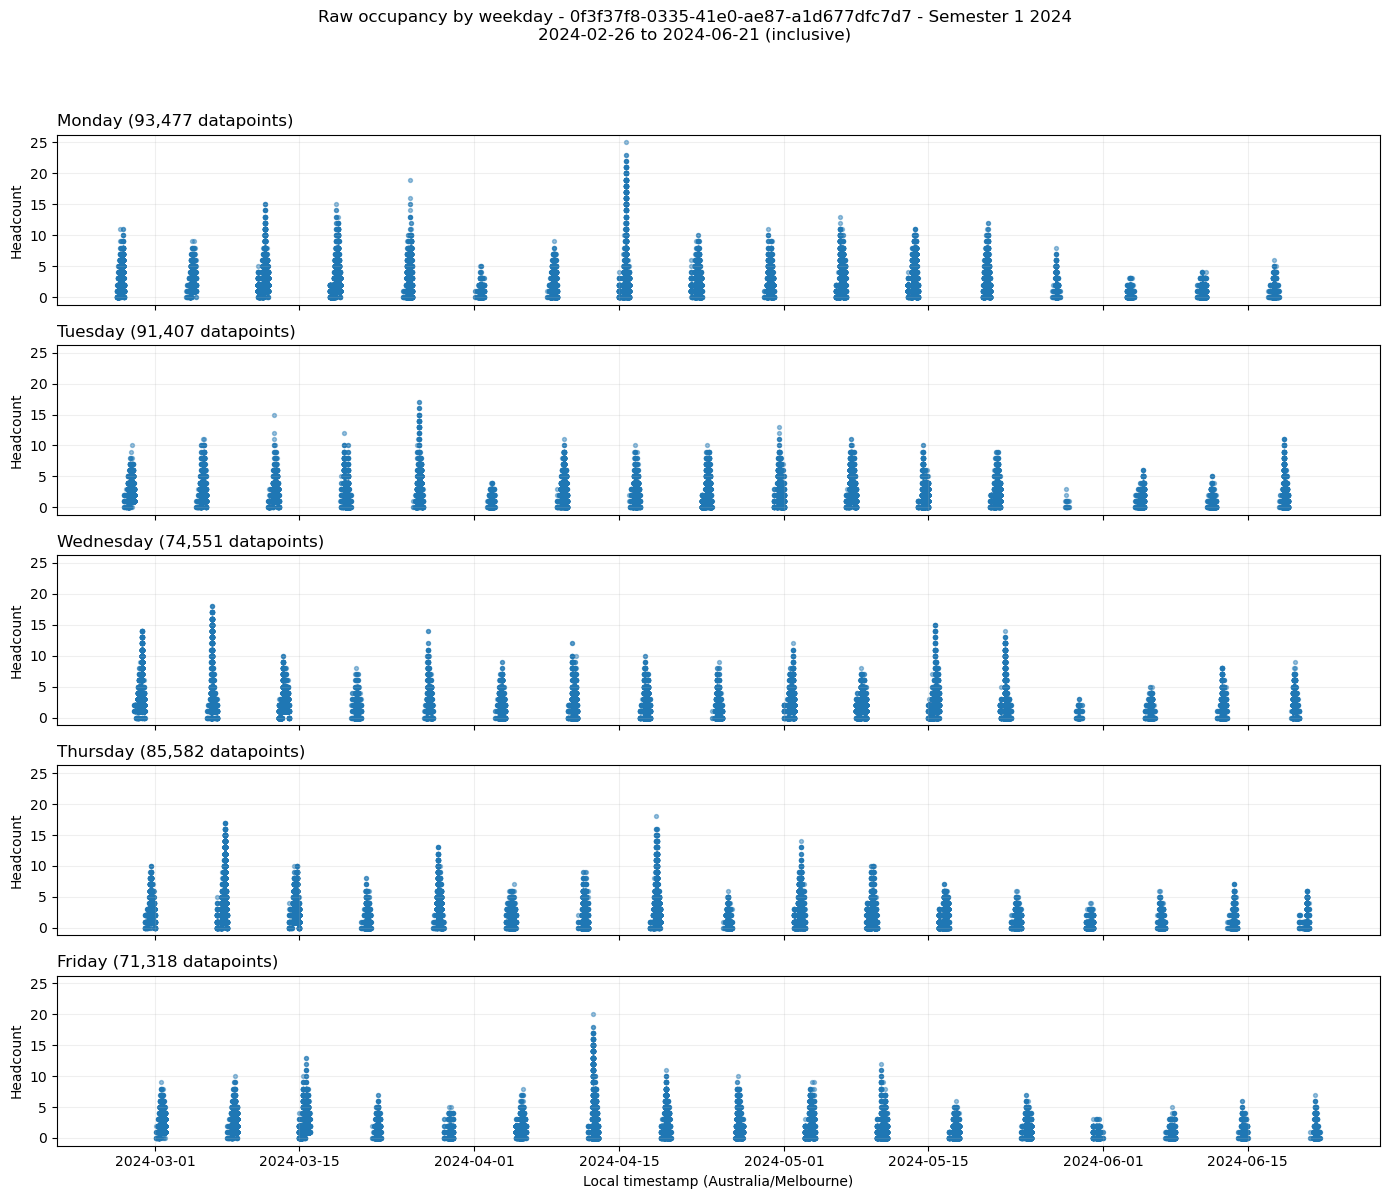

Floorspace: 0f3f37f8-0335-41e0-ae87-a1d677dfc7d7
Semester: Semester 1 2024 (2024-02-26 to 2024-06-21, inclusive)
Weekday source rows in semester: 416,335
Weekday rows with missing headcount (not plotted): 0
Raw datapoints plotted: 416,335
Plot saved to: C:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project\derived\weekday_occupancy_scatter\occupancy_scatter_0f3f37f8-0335-41e0-ae87-a1d677dfc7d7_2024-02-26_to_2024-06-21.png


,weekday,datapoints
0,Monday,93477
1,Tuesday,91407
2,Wednesday,74551
3,Thursday,85582
4,Friday,71318


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd

TIMEZONE = "Australia/Melbourne"
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
ROOT = Path.cwd().resolve()
while not (ROOT / "pre-Processing.ipynb").is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pre-Processing.ipynb").is_file():
    raise FileNotFoundError("Run this analysis from the project repository or one of its subdirectories.")

STREAM_DIR = ROOT / "derived" / "occupancy_streams_by_floorspace"
OUTPUT_DIR = ROOT / "derived" / "weekday_occupancy_scatter"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MANIFESTS = {"stream_row_counts.csv", "occupancystatuschangedate_audit.csv"}
STREAM_FILES = sorted(path for path in STREAM_DIR.glob("*.csv") if path.name not in MANIFESTS)
if not STREAM_FILES:
    raise FileNotFoundError(f"Processed occupancy streams not found: {STREAM_DIR}; run the preprocessing cell first.")

# Change these values to analyse one floorspace and one semester at a time.
FLOORSPACE_ID = "0f3f37f8-0335-41e0-ae87-a1d677dfc7d7"
SEMESTER_LABEL = "Semester 1 2024"
SEMESTER_START_DATE = "2024-02-26"
SEMESTER_END_DATE = "2024-06-21"

space_ids = [path.stem for path in STREAM_FILES]
print("Available floorspace IDs:")
for space_id in space_ids:
    print(f"  {space_id}")
if FLOORSPACE_ID not in space_ids:
    raise ValueError(f"Unknown floorspace {FLOORSPACE_ID!r}; choose one of the available IDs listed above.")
if pd.Timestamp(SEMESTER_START_DATE) > pd.Timestamp(SEMESTER_END_DATE):
    raise ValueError("SEMESTER_START_DATE must be on or before SEMESTER_END_DATE.")

semester_start = pd.Timestamp(SEMESTER_START_DATE).tz_localize(TIMEZONE)
semester_end_exclusive = (
    pd.Timestamp(SEMESTER_END_DATE) + pd.Timedelta(days=1)
).tz_localize(TIMEZONE)
stream_path = STREAM_DIR / f"{FLOORSPACE_ID}.csv"
weekday_parts = []
weekday_source_rows = 0
missing_headcount_rows = 0

# Read only the chosen floorspace; retain each source row without time-bin aggregation.
for chunk in pd.read_csv(
    stream_path,
    usecols=["collecteddate", "headcount"],
    dtype=str,
    keep_default_na=False,
    chunksize=250_000,
):
    timestamp_utc = pd.to_datetime(
        chunk["collecteddate"], format="mixed", errors="coerce", utc=True
    )
    if timestamp_utc.isna().any():
        raise ValueError(f"Invalid collecteddate found in {stream_path.name}.")

    headcount_text = chunk["headcount"].str.strip().replace("", pd.NA)
    headcount = pd.to_numeric(headcount_text, errors="coerce")
    invalid_headcount = headcount_text.notna() & headcount.isna()
    if invalid_headcount.any() or (headcount.dropna() < 0).any():
        raise ValueError(f"Invalid headcount found in {stream_path.name}.")

    local_timestamp = timestamp_utc.dt.tz_convert(TIMEZONE)
    in_semester = (local_timestamp >= semester_start) & (
        local_timestamp < semester_end_exclusive
    )
    weekday = local_timestamp.dt.day_name()
    is_weekday = in_semester & weekday.isin(WEEKDAYS)
    weekday_source_rows += int(is_weekday.sum())
    missing_headcount_rows += int((is_weekday & headcount.isna()).sum())
    has_headcount = is_weekday & headcount.notna()
    if has_headcount.any():
        weekday_parts.append(
            pd.DataFrame(
                {
                    "local_timestamp": local_timestamp.loc[has_headcount],
                    "weekday": weekday.loc[has_headcount],
                    "headcount": headcount.loc[has_headcount],
                }
            )
        )

if not weekday_parts:
    raise ValueError(
        f"No valid weekday headcounts found for {FLOORSPACE_ID} during "
        f"{SEMESTER_LABEL} ({SEMESTER_START_DATE} to {SEMESTER_END_DATE})."
    )
observations = pd.concat(weekday_parts, ignore_index=True).sort_values("local_timestamp")

fig, axes = plt.subplots(len(WEEKDAYS), 1, figsize=(14, 12), sharex=True, sharey=True)
for ax, day in zip(axes, WEEKDAYS):
    day_observations = observations.loc[observations["weekday"].eq(day)]
    ax.scatter(
        day_observations["local_timestamp"],
        day_observations["headcount"],
        s=8,
        alpha=0.45,
        rasterized=True,
    )
    ax.set_ylabel("Headcount")
    ax.set_title(f"{day} ({len(day_observations):,} datapoints)", loc="left")
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel(f"Local timestamp ({TIMEZONE})")
fig.suptitle(
    f"Raw occupancy by weekday - {FLOORSPACE_ID} - {SEMESTER_LABEL}\n"
    f"{SEMESTER_START_DATE} to {SEMESTER_END_DATE} (inclusive)",
    y=0.995,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
output_path = OUTPUT_DIR / (
    f"occupancy_scatter_{FLOORSPACE_ID}_{SEMESTER_START_DATE}_to_{SEMESTER_END_DATE}.png"
)
fig.savefig(output_path, dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)

weekday_counts = (
    observations["weekday"].value_counts().reindex(WEEKDAYS, fill_value=0)
)
print(f"Floorspace: {FLOORSPACE_ID}")
print(f"Semester: {SEMESTER_LABEL} ({SEMESTER_START_DATE} to {SEMESTER_END_DATE}, inclusive)")
print(f"Weekday source rows in semester: {weekday_source_rows:,}")
print(f"Weekday rows with missing headcount (not plotted): {missing_headcount_rows:,}")
print(f"Raw datapoints plotted: {len(observations):,}")
print(f"Plot saved to: {output_path}")
display(weekday_counts.rename("datapoints").rename_axis("weekday").reset_index())